<a href="https://colab.research.google.com/github/asishprusty2468-lgtm/Lorenz-84-model/blob/main/lorenzmodel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saved lorenz84_error_growth.png


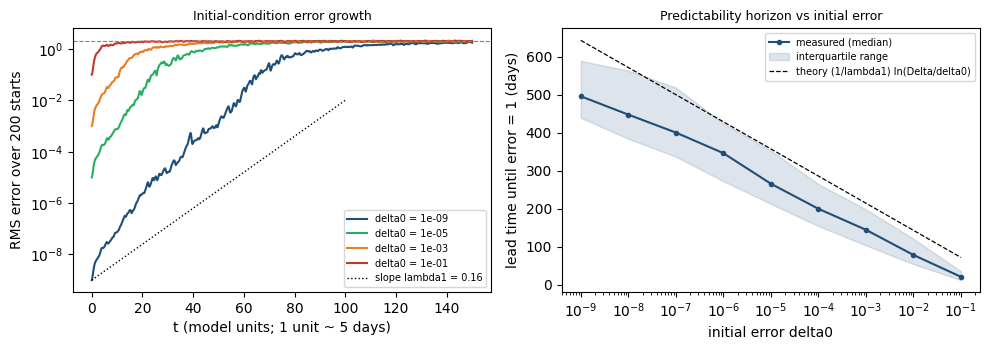

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
colors = {1e-9: "#1f4e79", 1e-5: "#27ae60", 1e-3: "#e67e22", 1e-1: "#c0392b"}
t = np.arange(n_steps + 1)*DT
for d0, rms in rms_curves.items():
    for key, col in colors.items():
        if abs(np.log10(key) - np.log10(d0)) < 1e-6:
            axs[0].semilogy(t, rms, color=col, label=f"delta0 = {d0:.0e}")
axs[0].axhline(saturation, color="gray", ls="--", lw=0.8)
tg = np.linspace(0, 100, 50)
axs[0].semilogy(tg, 1e-9*np.exp(lam1*tg), "k:", lw=1.0, label=f"slope lambda1 = {lam1:.2f}")
axs[0].set_xlabel("t (model units; 1 unit ~ 5 days)")
axs[0].set_ylabel(f"RMS error over {N_STARTS} starts")
axs[0].set_title("Initial-condition error growth", fontsize=9)
axs[0].legend(fontsize=7)

axs[1].semilogx(D0_LIST, 5*Tp_median, "o-", color="#1f4e79", ms=3, label="measured (median)")
axs[1].fill_between(D0_LIST, 5*Tp_q25, 5*Tp_q75, color="#1f4e79", alpha=0.15, label="interquartile range")
axs[1].semilogx(D0_LIST, 5*(1/lam1)*np.log(THRESHOLD/D0_LIST), "k--", lw=0.9,
                label="theory (1/lambda1) ln(Delta/delta0)")
axs[1].set_xlabel("initial error delta0")
axs[1].set_ylabel(f"lead time until error = {THRESHOLD:g} (days)")
axs[1].set_title("Predictability horizon vs initial error", fontsize=9)
axs[1].legend(fontsize=7)
plt.tight_layout()
# plt.savefig("lorenz84_error_growth.png", dpi=200)
print("Saved lorenz84_error_growth.png")
plt.show()

In [ ]:
import numpy as np
from scipy.integrate import odeint

# System parameters
a = 0.25
b = 4.0
F = 8.0
G = 1

def lorenz84_extended(Y, t):
    x, y, z = Y[0], Y[1], Y[2]
    Phi = Y[3:].reshape((3, 3))

    # Lorenz-84 equations
    dxdt = -y**2 - z**2 - a*x + a*F
    dydt = x*y - b*x*z - y + G
    dzdt = b*x*y + x*z - z

    # Jacobian matrix
    J = np.array([
        [-a, -2*y, -2*z],
        [y - b*z, x - 1, -b*x],
        [b*y + z, b*x, x - 1]
    ])

    dPhidt = J @ Phi
    return np.hstack(([dxdt, dydt, dzdt], dPhidt.flatten()))

# 1. Warm-up to reach attractor
X0 = np.array([1.0, 1.0, 1.0])
Phi0 = np.eye(3)
state = np.hstack((X0, Phi0.flatten()))
dt = 0.1
t_warmup = np.arange(0, 300, dt)
warmup_sol = odeint(lorenz84_extended, state, t_warmup)
state = warmup_sol[-1, :]
state = np.hstack((state[:3], np.eye(3).flatten()))
# 2. Benettin integration with QR decomposition
T_total = 3000.0
n_steps = int(T_total / dt)
cum_log_R = np.zeros(3)
x_samples = []

for step in range(n_steps):
    sol = odeint(lorenz84_extended, state, [0, dt])
    end_state = sol[-1, :]
    x_val = end_state[0]
    x_samples.append(x_val)

    # Extract Phi and perform QR decomposition
    Phi = end_state[3:].reshape((3, 3))
    Q, R = np.linalg.qr(Phi)

    # Ensure positive diagonal for R
    diag_sign = np.sign(np.diag(R))
    Q = Q * diag_sign
    R = diag_sign[:, None] * R

    cum_log_R += np.log(np.diag(R))

    # Reset Phi to orthonormal Q
    state = np.hstack((end_state[:3], Q.flatten()))

# 3. Compute final quantities
lambda_vals = cum_log_R / T_total
l1, l2, l3 = lambda_vals[0], lambda_vals[1], lambda_vals[2]
D_ky = 2 + (l1 + l2) / abs(l3)
t_double = np.log(2) / l1
mean_x = np.mean(x_samples)

print(f"lambda_1 = {l1:+.4f}")
print(f"lambda_2 = {l2:+.4f}")
print(f"lambda_3 = {l3:+.4f}")
print(f"Sum = {sum(lambda_vals):.4f} (Predicted: {-a - 2 + 2*mean_x:.4f})")
print(f"Doubling time T_d = {t_double:.2f} units")


lambda_1 = +0.1645
lambda_2 = -0.0000
lambda_3 = -0.3723
Sum = -0.2078 (Predicted: -0.2078)
Doubling time T_d = 4.21 units


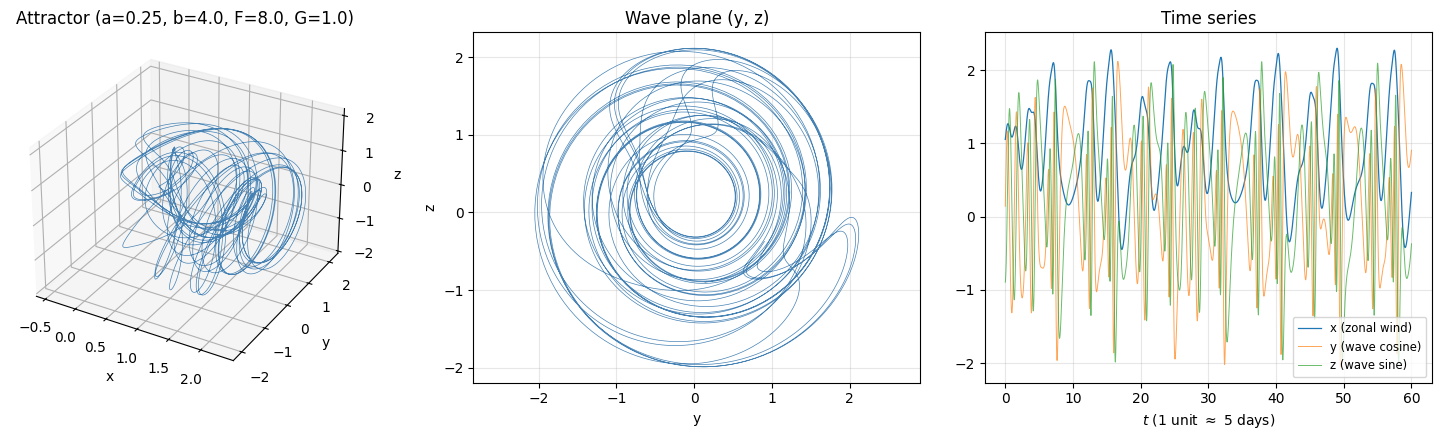

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 1. Standard Parameters (from Section 2.1 of guide)
a, b, F, G = 0.25, 4.0, 8.0, 1.0
dt = 0.01

# 2. Governing Equations (Lorenz-84 Model)
def f(s):
    x, y, z = s
    dxdt = -y**2 - z**2 - a*x + a*F
    dydt = x*y - b*x*z - y + G
    dzdt = b*x*y + x*z - z
    return np.array([dxdt, dydt, dzdt])

# 3. 4th-Order Runge-Kutta Integrator
def rk4(s, dt):
    k1 = f(s)
    k2 = f(s + 0.5 * dt * k1)
    k3 = f(s + 0.5 * dt * k2)
    k4 = f(s + dt * k3)
    return s + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

# 4. Integrate Trajectory
s = np.array([1.0, 1.0, 1.0])

# Discard transients so the trajectory settles onto the attractor
for _ in range(5000):
    s = rk4(s, dt)

# Record data for T = 60 time units (6000 steps)
n_steps = 6000
traj = np.zeros((n_steps, 3))
time = np.linspace(0, n_steps * dt, n_steps)

for i in range(n_steps):
    s = rk4(s, dt)
    traj[i] = s

x, y, z = traj[:, 0], traj[:, 1], traj[:, 2]

# 5. Plotting Figure 2
fig = plt.figure(figsize=(15, 4.5))

# Subplot 1: 3D Attractor
ax1 = fig.add_subplot(131, projection='3d')
ax1.plot(x, y, z, lw=0.5, color='steelblue')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_zlabel('z')
ax1.set_title(f'Attractor (a={a}, b={b}, F={F}, G={G})')

# Subplot 2: Wave plane (y, z)
ax2 = fig.add_subplot(132)
ax2.plot(y, z, lw=0.5, color='steelblue')
ax2.set_xlabel('y')
ax2.set_ylabel('z')
ax2.set_title('Wave plane (y, z)')
ax2.axis('equal')
ax2.grid(True, alpha=0.3)

# Subplot 3: Time series
ax3 = fig.add_subplot(133)
ax3.plot(time, x, lw=0.9, label='x (zonal wind)', color='tab:blue')
ax3.plot(time, y, lw=0.7, label='y (wave cosine)', color='tab:orange', alpha=0.7)
ax3.plot(time, z, lw=0.7, label='z (wave sine)', color='tab:green', alpha=0.7)
ax3.set_xlabel(r'$t$ (1 unit $\approx$ 5 days)')
ax3.set_title('Time series')
ax3.legend(loc='lower right', fontsize='small')
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Bifurcation diagram: removing transient...
Lyapunov exponent versus F...

F values with lambda1 > 0.01 (chaotic):
  F from about 4.37 to 4.77
  F from about 4.87 to 4.87
  F from about 4.97 to 5.07
  F from about 5.17 to 5.17
  F from about 7.13 to 7.13
  F from about 7.44 to 7.69
  F from about 7.84 to 8.09
  F from about 8.24 to 8.79
Largest lambda1 found: +0.218 at F = 7.54
lambda1 near F = 8 (standard value): +0.143


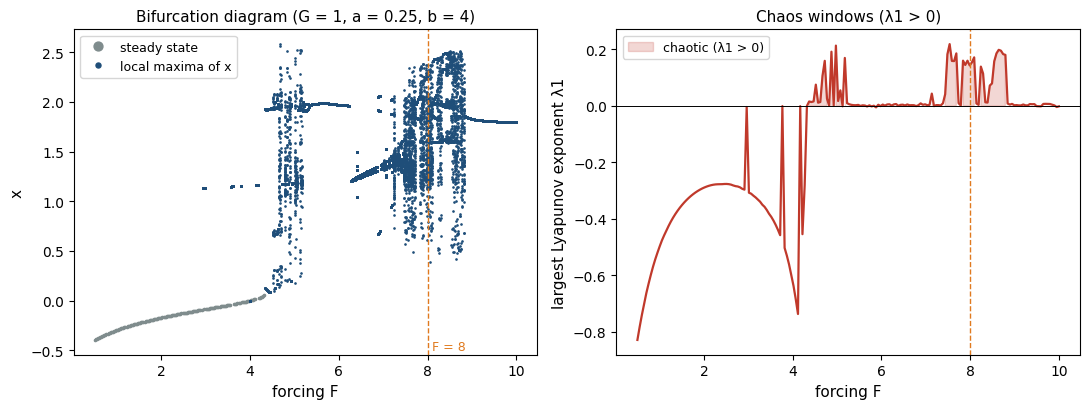

In [1]:
# ----------------------------------------------------------------
# Lorenz (1984) model: bifurcation-style diagram and largest Lyapunov exponent versus F
# ----------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------------- settings
a, b, G = 0.25, 4.0, 1.0  # fixed parameters (standard values)
F_MIN, F_MAX = 0.5, 10.0  # range of F that is scanned

# In Colab, we can use the full precision run.
# Set QUICK = True if you want a fast 5-second test.
QUICK = False

N_F_BIF = 150 if QUICK else 400   # number of F values for the bifurcation diagram
N_F_LYAP = 60 if QUICK else 190   # number of F values for the lambda1 curve
T_TRANS = 150 if QUICK else 300   # transient (discarded), model units
T_RECORD = 75 if QUICK else 150   # recording time for the diagram, model units
T_LYAP = 150 if QUICK else 400    # averaging time for lambda1, model units
DT = 0.02                         # RK4 time step
ZERO_TOL = 0.01                   # |lambda1| below this is treated as zero

# ---------------------------------------------------------------- the model (vectorised over F)
def f(s, F):
    """s has shape (nF, 3); F has shape (nF,)."""
    x, y, z = s[:, 0], s[:, 1], s[:, 2]
    return np.stack([-y*y - z*z - a*x + a*F, x*y - b*x*z - y + G, b*x*y + x*z - z], axis=1)

def jac(s):
    """Jacobian for every state: shape (nF, 3, 3)."""
    x, y, z = s[:, 0], s[:, 1], s[:, 2]
    J = np.zeros((len(s), 3, 3))
    J[:, 0, 0] = -a;    J[:, 0, 1] = -2*y;  J[:, 0, 2] = -2*z
    J[:, 1, 0] = y-b*z; J[:, 1, 1] = x - 1; J[:, 1, 2] = -b*x
    J[:, 2, 0] = b*y+z; J[:, 2, 1] = b*x;   J[:, 2, 2] = x - 1
    return J

def rk4(s, F, dt):
    k1 = f(s, F)
    k2 = f(s + 0.5*dt*k1, F)
    k3 = f(s + 0.5*dt*k2, F)
    k4 = f(s + dt*k3, F)
    return s + dt/6*(k1 + 2*k2 + 2*k3 + k4)

# ---------------------------------------------------------------- 1. bifurcation diagram
F_bif = np.linspace(F_MIN, F_MAX, N_F_BIF)
s = np.tile([1.0, 1.0, 1.0], (N_F_BIF, 1))

print("Bifurcation diagram: removing transient...")
for _ in range(int(T_TRANS/DT)):
    s = rk4(s, F_bif, DT)

n_rec = int(T_RECORD/DT)
x_rec = np.empty((n_rec, N_F_BIF))
for i in range(n_rec):
    s = rk4(s, F_bif, DT)
    x_rec[i] = s[:, 0]

steady_F, steady_x, max_F, max_x = [], [], [], []
for j, Fv in enumerate(F_bif):
    x = x_rec[:, j]
    idx = np.where((x[1:-1] > x[:-2]) & (x[1:-1] > x[2:]))[0] + 1  # local maxima
    if len(idx) == 0:  # no oscillation -> steady state
        steady_F.append(Fv); steady_x.append(x[-1])
    else:
        max_F.extend([Fv]*len(idx)); max_x.extend(x[idx])

# ---------------------------------------------------------------- 2. lambda1 versus F
F_lyap = np.linspace(F_MIN, F_MAX, N_F_LYAP)
nF = len(F_lyap)
s = np.tile([1.0, 1.0, 1.0], (nF, 1))

for _ in range(int(T_TRANS/DT)):  # transient (state only, NOT the tangent matrix)
    s = rk4(s, F_lyap, DT)

print("Lyapunov exponent versus F...")
Q = np.tile(np.eye(3), (nF, 1, 1))  # tangent vectors start as identity AFTER the transient
log_sum = np.zeros(nF)
n_steps = int(T_LYAP/DT)

for i in range(1, n_steps + 1):
    # RK4 for state and tangent matrix together
    k1s = f(s, F_lyap);   k1Q = jac(s) @ Q
    s2 = s + 0.5*DT*k1s
    k2s = f(s2, F_lyap);  k2Q = jac(s2) @ (Q + 0.5*DT*k1Q)
    s3 = s + 0.5*DT*k2s
    k3s = f(s3, F_lyap);  k3Q = jac(s3) @ (Q + 0.5*DT*k2Q)
    s4 = s + DT*k3s
    k4s = f(s4, F_lyap);  k4Q = jac(s4) @ (Q + DT*k3Q)

    s = s + DT/6*(k1s + 2*k2s + 2*k3s + k4s)
    Q = Q + DT/6*(k1Q + 2*k2Q + 2*k3Q + k4Q)

    if i % 10 == 0:  # re-orthonormalise (Benettin / QR)
        Q, R = np.linalg.qr(Q)
        log_sum += np.log(np.abs(R[:, 0, 0]))  # growth of the first vector = lambda1

lam1 = log_sum/(n_steps*DT)

# ---------------------------------------------------------------- 3. report chaotic windows
chaotic = lam1 > ZERO_TOL
print(f"\nF values with lambda1 > {ZERO_TOL} (chaotic):")
start = None
for k in range(nF):
    if chaotic[k] and start is None:
        start = F_lyap[k]
    if (not chaotic[k] or k == nF - 1) and start is not None:
        end = F_lyap[k-1] if not chaotic[k] else F_lyap[k]
        print(f"  F from about {start:.2f} to {end:.2f}")
        start = None

print(f"Largest lambda1 found: {lam1.max():+.3f} at F = {F_lyap[lam1.argmax()]:.2f}")
i8 = np.argmin(abs(F_lyap - 8.0))
print(f"lambda1 near F = 8 (standard value): {lam1[i8]:+.3f}")

# ---------------------------------------------------------------- 4. figure
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))

# Left plot: Bifurcation
axs[0].plot(steady_F, steady_x, "o", ms=1.6, color="#7f8c8d", label="steady state")
axs[0].plot(max_F, max_x, "o", ms=0.9, color="#1f4e79", label="local maxima of x")
axs[0].axvline(8, color="#E07A1F", ls="--", lw=1)
axs[0].text(8.1, axs[0].get_ylim()[0] + 0.05, "F = 8", color="#E07A1F", fontsize=9)
axs[0].set_xlabel("forcing F", fontsize=11)
axs[0].set_ylabel("x", fontsize=11)
axs[0].set_title("Bifurcation diagram (G = 1, a = 0.25, b = 4)", fontsize=11)
axs[0].legend(fontsize=9, loc="upper left", markerscale=4)

# Right plot: Lyapunov
axs[1].plot(F_lyap, lam1, "-", color="#c0392b", lw=1.6)
axs[1].axhline(0, color="k", lw=0.7)
axs[1].fill_between(F_lyap, 0, lam1, where=chaotic, color="#c0392b", alpha=0.2, label="chaotic (λ1 > 0)")
axs[1].axvline(8, color="#E07A1F", ls="--", lw=1)
axs[1].set_xlabel("forcing F", fontsize=11)
axs[1].set_ylabel("largest Lyapunov exponent λ1", fontsize=11)
axs[1].set_title("Chaos windows (λ1 > 0)", fontsize=11)
axs[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig("lorenz84_bifurcation.png", dpi=200) # Still saves the file to your Colab workspace
plt.show() # Forces Colab to display the plot output underneath the cell
